# CMP6202 – Notebook 04: Evaluation and further modelling improvements

Evidence for report section **5** (Steps 1–7). The test set is used here for the first time. The selection rule was
fixed beforehand, on the training set:

> *Final model = the highest cross-validated macro F1; models within one standard deviation of the best are tied, and
> a tie is broken by the lower inference time.*

In [1]:
# Google Colab setup. On a local machine this cell does nothing.
# On Colab: upload the project folder to Google Drive (README, "Run on Google Colab"). The cell mounts Drive,
# finds the folder, installs the pinned libraries and makes `nids` importable.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    from importlib.metadata import version

    from google.colab import drive

    drive.mount("/content/drive")
    # I accept both upload locations the README describes and pick the one that holds the nids package.
    candidates = ["/content/drive/MyDrive/CMP6202_NIDS/Project", "/content/drive/MyDrive/Project"]
    found = [path for path in candidates if os.path.isdir(os.path.join(path, "src", "nids"))]
    if not found:
        raise SystemExit(f"Project folder not found on Drive; looked in {candidates}")
    PROJECT_DIR = found[0]
    os.chdir(PROJECT_DIR)
    loaded = {name: version(dist) for name, dist in (("numpy", "numpy"), ("pandas", "pandas"), ("sklearn", "scikit-learn"))
              if name in sys.modules}
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
    sys.path.insert(0, os.path.join(PROJECT_DIR, "src"))
    changed = [name for name, old in loaded.items()
               if old != version({"sklearn": "scikit-learn"}.get(name, name))]
    if changed:
        # A library that was already imported cannot be replaced in a running session.
        raise SystemExit(f"Upgraded {changed}: choose Runtime > Restart session, then run this cell again.")
    print("Running on Colab from", PROJECT_DIR)
else:
    print("Running locally; Colab setup skipped")

Running locally; Colab setup skipped


## **Import the libraries and load the tuned models**

In [2]:
import os
import time
import warnings

import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

from nids import config, data, eda, evaluation, features, models, plotting, predict, report_numbers  # src/nids

plotting.apply_style()
warnings.filterwarnings("ignore", category=FutureWarning)

sample = data.load_sample()
split = data.load_split(sample)
data.assert_no_leakage(split)
X_train, y_train, X_test, y_test = split.X_train, split.y_train, split.X_test, split.y_test
# The searches fitted in notebook 03, loaded from models/ (NIDS_FORCE_RETRAIN=1 refits them).
runs = {name: models.load_or_run_search(name, X_train, y_train, force=os.environ.get("NIDS_FORCE_RETRAIN") == "1")
        for name in models.MODEL_NAMES}
y_test.value_counts()

Label
Benign            12715
SSH-Bruteforce     2276
FTP-BruteForce        9
Name: count, dtype: int64

# 5 Evaluation and further modelling improvements

### Step 1: Model Selection

Nominal three-class target, so classification with the eight algorithms of report section 3.1.

### Step 2: Data Preparation

Cleaning, de-duplication and the 80/20 split are in notebooks 01–02; encoding, scaling and SMOTE are fitted inside the
pipeline. One fitted pipeline:

In [3]:
runs[models.TREE].search.best_estimator_

,steps,"[('preprocess', ...), ('resample', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[object](3,)","['Benign','FTP-BruteForce','SSH-Bruteforce']"
feature_names_in_,"ndarray[object](79,)","['Dst Port','Protocol','Timestamp',...,'Idle Std','Idle Max','Idle Min']"
n_features_in_,int,79
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('protocol', ...), ('numeric', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'


### Step 3: Model Development

Each tuned model (refitted on the 60,000 training flows in notebook 03) predicts the 15,000 test flows.

In [4]:
predictions, test_rows = {}, []
for name, run in runs.items():
    model = run.search.best_estimator_
    predictions[name] = model.predict(X_test)
    scores = evaluation.score_predictions(y_test, predictions[name])
    low, high = evaluation.bootstrap_interval(y_test, predictions[name], "f1_macro")  # 95% stratified bootstrap
    test_rows.append({"model": name, **scores, "f1_macro_ci_low": low, "f1_macro_ci_high": high,
                      "test_errors": int((predictions[name] != y_test.to_numpy()).sum()),
                      "inference_ms_per_1000": evaluation.inference_ms_per_1000(model, X_test)})
test_results = pd.DataFrame(test_rows).set_index("model")
test_results.round(6).to_csv(config.TABLES_DIR / "5_1_test_results.csv")
test_results.round(5)

,accuracy,f1_weighted,f1_macro,precision_macro,recall_macro,recall_ftp,f1_macro_ci_low,f1_macro_ci_high,test_errors,inference_ms_per_1000
model,,,,,,,,,,
Decision Tree,0.99987,0.99987,0.99983,0.99983,0.99983,1.0,0.99957,1.0,2,0.50746
Random Forest,0.99993,0.99994,0.98244,0.96667,0.99997,1.0,0.95234,1.0,1,2.88436
Gaussian Naive Bayes,0.99980,0.99980,0.99974,0.99992,0.99956,1.0,0.99939,1.0,3,1.08151
k-Nearest Neighbours,0.99993,0.99993,0.99991,0.99985,0.99997,1.0,0.99974,1.0,1,30.78030
Logistic Regression,0.99980,0.99981,0.96655,0.93925,0.99992,1.0,0.91659,1.0,3,1.19061
Support Vector Machine,0.99987,0.99987,0.98236,0.96652,0.99995,1.0,0.95191,1.0,2,2.12116
Gradient Boosting,1.00000,1.00000,1.00000,1.00000,1.00000,1.0,1.00000,1.0,0,8.03054
Multi-layer Perceptron,0.99993,0.99994,0.98244,0.96667,0.99997,1.0,0.95234,1.0,1,1.62511


In [5]:
per_class = pd.concat({name: evaluation.per_class_report(y_test, p) for name, p in predictions.items()})
per_class.round(6).to_csv(config.TABLES_DIR / "5_1_test_per_class.csv")
test_errors = pd.DataFrame([
    {"model": n, "true": t, "predicted": p, "flows": int(((y_test.to_numpy() == t) & (pred == p)).sum())}
    for n, pred in predictions.items() for t in plotting.CLASS_ORDER for p in plotting.CLASS_ORDER if t != p
]).query("flows > 0")
(test_errors.pivot_table(index="model", columns=["true", "predicted"], values="flows", fill_value=0)
            .reindex(models.MODEL_NAMES).fillna(0).astype(int))

true                           Benign                SSH-Bruteforce
predicted              FTP-BruteForce SSH-Bruteforce         Benign
model                                                              
Decision Tree                       0              1              1
Random Forest                       1              0              0
Gaussian Naive Bayes                0              0              3
k-Nearest Neighbours                0              1              0
Logistic Regression                 2              1              0
Support Vector Machine              1              1              0
Gradient Boosting                   0              0              0
Multi-layer Perceptron              1              0              0

### Step 4: Model Evaluation

Accuracy and macro-averaged precision, recall and F1 (the nine FTP flows count as much as 12,715 benign ones),
confusion matrices, and the `classification_report` of the Week 4 lab.

--- Gradient Boosting ---
                precision    recall  f1-score   support

        Benign     1.0000    1.0000    1.0000     12715
FTP-BruteForce     1.0000    1.0000    1.0000         9
SSH-Bruteforce     1.0000    1.0000    1.0000      2276

      accuracy                         1.0000     15000
     macro avg     1.0000    1.0000    1.0000     15000
  weighted avg     1.0000    1.0000    1.0000     15000

--- Gaussian Naive Bayes ---
                precision    recall  f1-score   support

        Benign     0.9998    1.0000    0.9999     12715
FTP-BruteForce     1.0000    1.0000    1.0000         9
SSH-Bruteforce     1.0000    0.9987    0.9993      2276

      accuracy                         0.9998     15000
     macro avg     0.9999    0.9996    0.9997     15000
  weighted avg     0.9998    0.9998    0.9998     15000



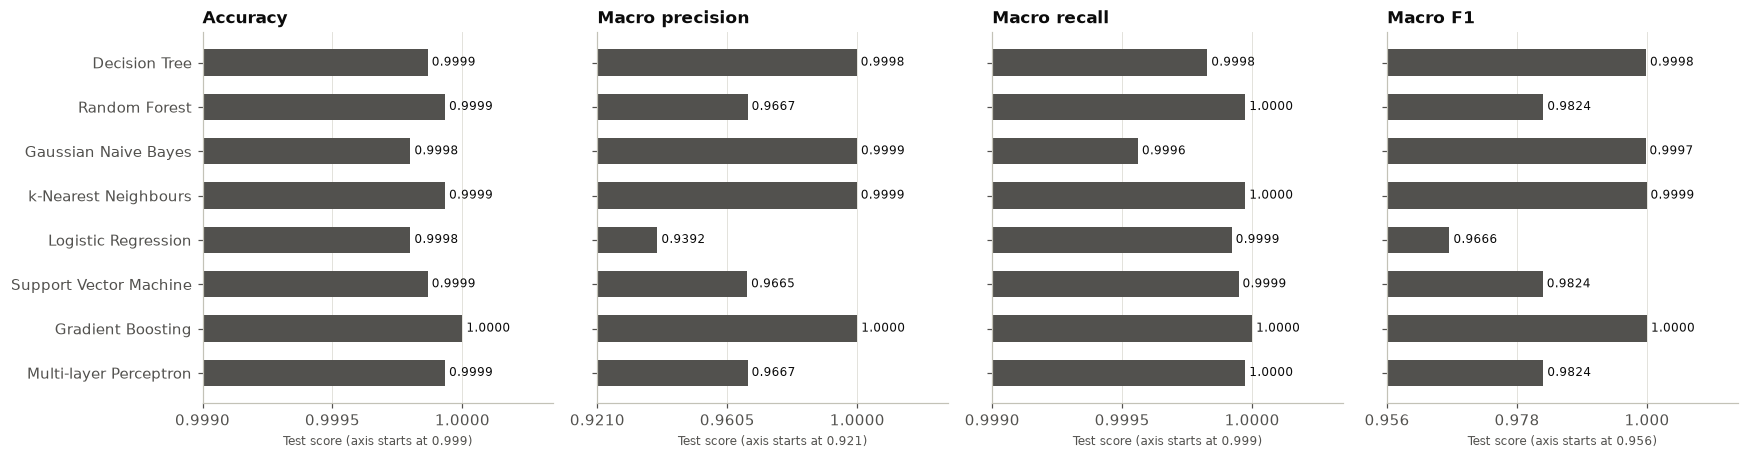

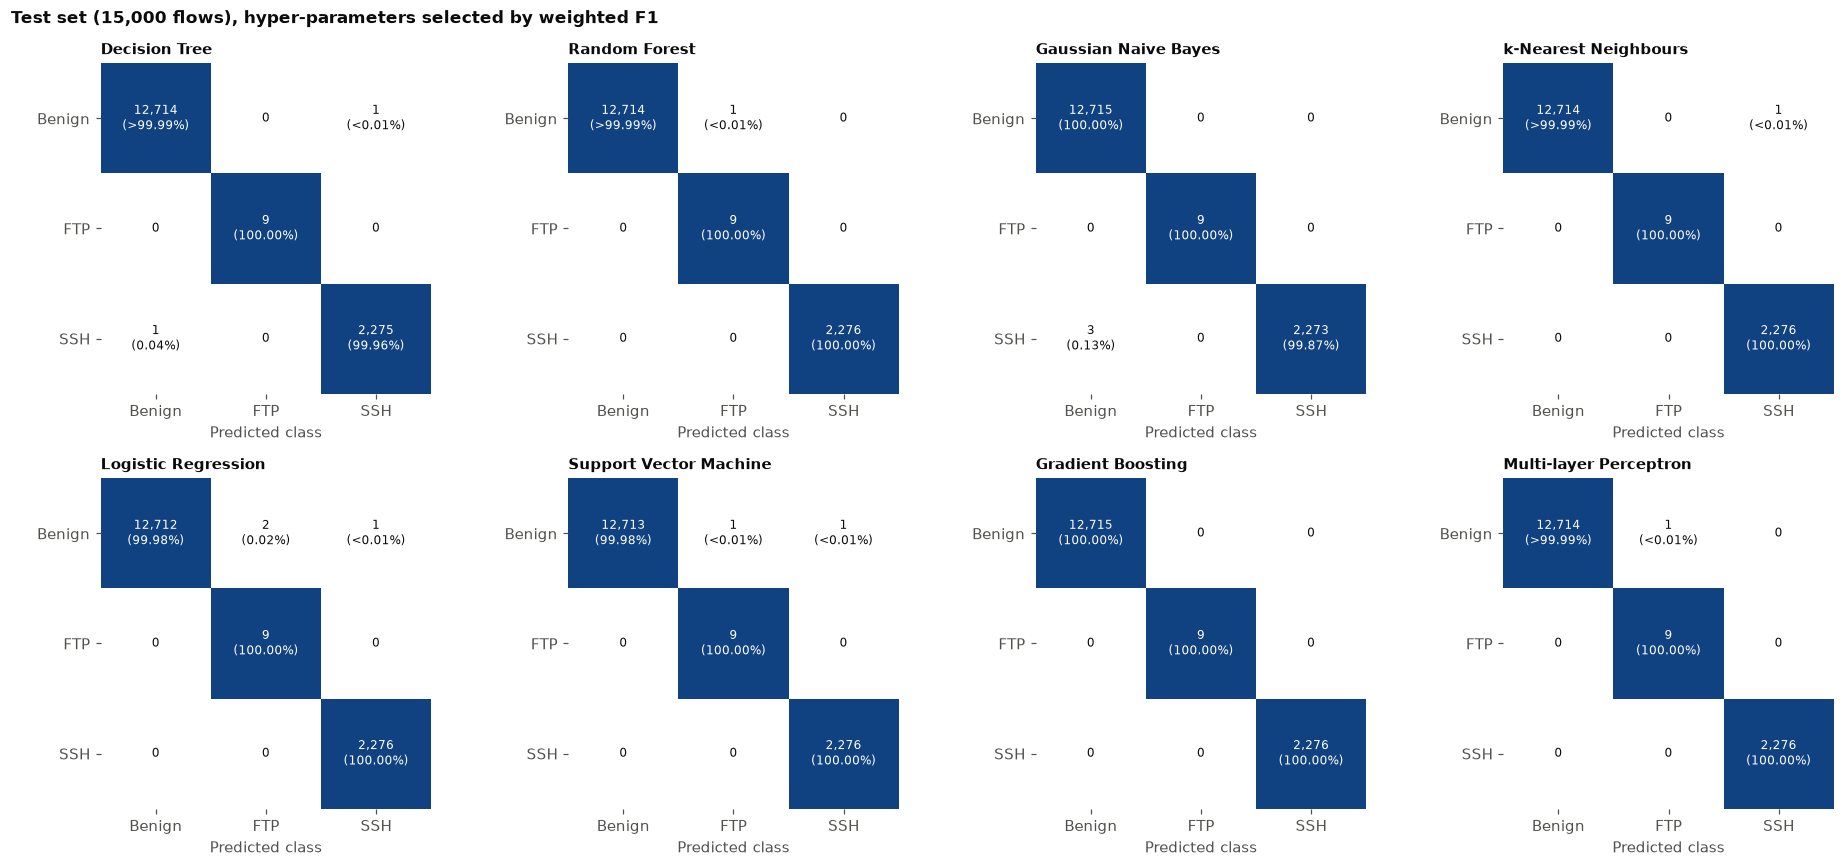

In [6]:
metric_labels = {"accuracy": "Accuracy", "precision_macro": "Macro precision",
                 "recall_macro": "Macro recall", "f1_macro": "Macro F1"}
fig = plotting.plot_metric_bars(test_results, metric_labels)
plotting.save_figure(fig, "5_4_test_metrics_by_model")
fig = plotting.plot_confusion_matrices({n: (y_test.to_numpy(), p) for n, p in predictions.items()},
                                       "Test set (15,000 flows), hyper-parameters selected by weighted F1")
plotting.save_figure(fig, "5_4_confusion_matrices_test")

for name in (test_results["test_errors"].idxmin(), test_results["test_errors"].idxmax()):
    print(f"--- {name} ---")
    print(classification_report(y_test, predictions[name], digits=4, zero_division=0))

**Feature importance (Week 6 lab):** impurity importance of the tuned Decision Tree and Random Forest.

Decision Tree: 10 features used; top 3 hold 99.6%. Random Forest: top 3 hold 27.5%


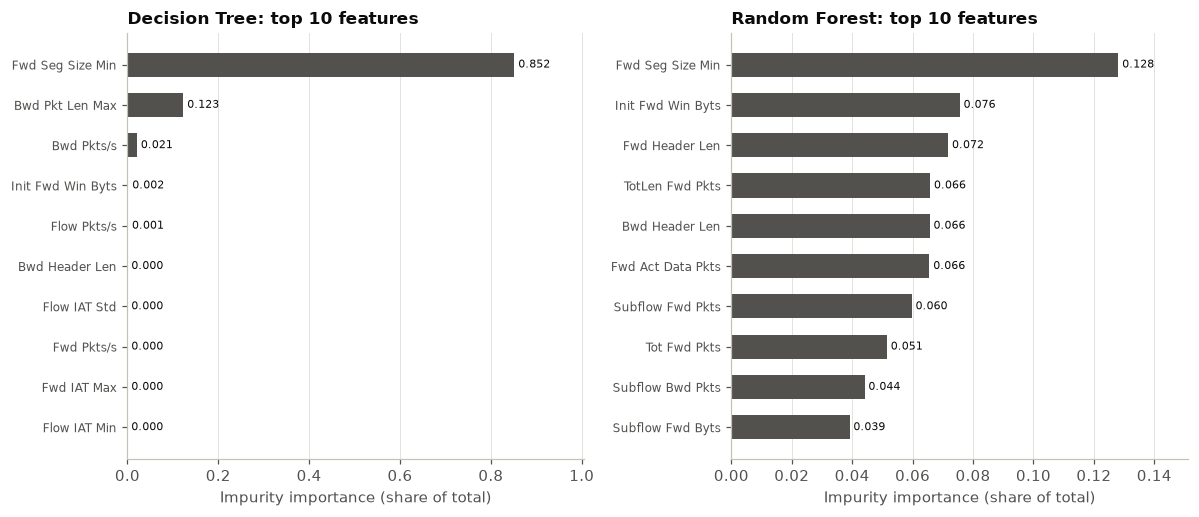

In [7]:
def impurity_importance(model) -> pd.Series:
    names = model.named_steps["preprocess"].get_feature_names_out()
    return pd.Series(model.named_steps["model"].feature_importances_, index=names)


dt_importance = impurity_importance(runs[models.TREE].search.best_estimator_)
rf_importance = impurity_importance(runs[models.FOREST].search.best_estimator_)
fig = plotting.plot_importance_pair(dt_importance, rf_importance, (models.TREE, models.FOREST), top=10)
plotting.save_figure(fig, "5_4_importance_dt_rf")
dt_used = int((dt_importance > 0).sum())
dt_top3_share, rf_top3_share = dt_importance.nlargest(3).sum(), rf_importance.nlargest(3).sum()
print(f"Decision Tree: {dt_used} features used; top 3 hold {dt_top3_share:.1%}. Random Forest: top 3 hold {rf_top3_share:.1%}")

### Step 5: Model Improvement

All decided by cross-validation on the training set.

**(i) Re-select hyper-parameters by macro F1.** Weighted F1 is saturated (notebook 03), so I take the setting with the
best cross-validated macro F1 from the same search and refit it.

In [8]:
macro_rows, macro_predictions, macro_models = [], {}, {}
for name, run in runs.items():
    pipeline, params, index = evaluation.selected_pipeline(run, "f1_macro")
    model, fit_seconds = evaluation.fit_timed(pipeline, X_train, y_train)
    macro_models[name], macro_predictions[name] = model, model.predict(X_test)
    res = run.search.cv_results_
    scores = evaluation.score_predictions(y_test, macro_predictions[name])
    low, high = evaluation.bootstrap_interval(y_test, macro_predictions[name], "f1_macro")
    macro_rows.append({
        "model": name, "same setting as weighted F1": index == run.search.best_index_,
        "cv_f1_macro (weighted-selected)": res["mean_test_f1_macro"][run.search.best_index_],
        "cv_f1_macro (macro-selected)": res["mean_test_f1_macro"][index],
        "cv_f1_macro_std": res["std_test_f1_macro"][index],
        "test_f1_macro": scores["f1_macro"], "test_ci_low": low, "test_ci_high": high,
        "test_accuracy": scores["accuracy"], "test_precision_macro": scores["precision_macro"],
        "test_recall_macro": scores["recall_macro"], "test_recall_ftp": scores["recall_ftp"],
        "test_errors": int((macro_predictions[name] != y_test.to_numpy()).sum()), "fit_seconds": fit_seconds,
        "inference_ms_per_1000": evaluation.inference_ms_per_1000(model, X_test), "params": params,
    })
macro_selection = pd.DataFrame(macro_rows).set_index("model")
macro_selection.drop(columns="params").round(6).to_csv(config.TABLES_DIR / "5_5_macro_selection.csv")
macro_selection.drop(columns="params").round(5)

,same setting as weighted F1,cv_f1_macro (weighted-selected),cv_f1_macro (macro-selected),cv_f1_macro_std,test_f1_macro,test_ci_low,test_ci_high,test_accuracy,test_precision_macro,test_recall_macro,test_recall_ftp,test_errors,fit_seconds,inference_ms_per_1000
model,,,,,,,,,,,,,,
Decision Tree,False,0.99030,0.99534,0.00890,0.99991,0.99974,1.0,0.99993,0.99985,0.99997,1.0,1,0.45088,0.56096
Random Forest,True,0.99549,0.99549,0.00892,0.98244,0.95234,1.0,0.99993,0.96667,0.99997,1.0,1,3.71497,2.92358
Gaussian Naive Bayes,True,0.99952,0.99952,0.00029,0.99974,0.99939,1.0,0.99980,0.99992,0.99956,1.0,3,0.28351,1.08874
k-Nearest Neighbours,True,0.99998,0.99998,0.00004,0.99991,0.99974,1.0,0.99993,0.99985,0.99997,1.0,1,0.26667,30.61001
Logistic Regression,False,0.97928,0.98368,0.01551,0.98236,0.95200,1.0,0.99987,0.96652,0.99995,1.0,2,0.64332,1.15083
Support Vector Machine,True,0.99547,0.99547,0.00891,0.98236,0.95191,1.0,0.99987,0.96652,0.99995,1.0,2,0.64953,2.12708
Gradient Boosting,True,0.99551,0.99551,0.00893,1.00000,1.00000,1.0,1.00000,1.00000,1.00000,1.0,0,3.14948,8.02759
Multi-layer Perceptron,False,0.98765,0.99534,0.00884,0.98227,0.95182,1.0,0.99980,0.96649,0.99980,1.0,3,2.53281,0.82799


**(ii) Regularisation as feature selection (Week 9, 2024 slides).** L1 (lasso) can set Logistic Regression coefficients to zero;
L2 (ridge) only shrinks them. In scikit-learn a smaller `C` means a stronger penalty.

In [9]:
lr_params = macro_selection.loc[models.LOGREG, "params"]
regularisation, lr_coefficients = models.cached(
    "logistic_regression_l1_l2_path",
    lambda: evaluation.regularisation_comparison(runs[models.LOGREG], X_train, y_train, lr_params), X_train)
regularisation.round(6).to_csv(config.TABLES_DIR / "5_5_l1_vs_l2.csv", index=False)

# The strongest L1 penalty whose macro F1 stays within one standard deviation of the selected model.
selected_cv = macro_selection.loc[models.LOGREG, "cv_f1_macro (macro-selected)"]
selected_sd = macro_selection.loc[models.LOGREG, "cv_f1_macro_std"]
l1 = regularisation[regularisation["penalty"] == "L1 (lasso)"]
sparse = l1[l1["cv_f1_macro_mean"] >= selected_cv - selected_sd].sort_values("features_used").iloc[0]
l2_same_c = regularisation[(regularisation["penalty"] == "L2 (ridge)") & (regularisation["C"] == sparse["C"])].iloc[0]
print(f"L1 with C = {sparse['C']:g} keeps {sparse['features_used']} features, CV macro F1 "
      f"{sparse['cv_f1_macro_mean']:.4f} (L2 at the same C: {l2_same_c['cv_f1_macro_mean']:.4f})")
regularisation.round(4)

L1 with C = 0.1 keeps 19 features, CV macro F1 0.9830 (L2 at the same C: 0.9671)


,C,penalty,train_f1_macro,cv_f1_macro_mean,cv_f1_macro_std,features_removed,features_used
0,67.3225,L2 (ridge),0.9849,0.9837,0.0155,0,69
1,67.3225,L1 (lasso),0.9849,0.9837,0.0155,0,69
2,1.0000,L2 (ridge),0.9788,0.9793,0.0132,0,69
3,1.0000,L1 (lasso),0.9829,0.9837,0.0155,22,47
4,0.1000,L2 (ridge),0.9667,0.9671,0.0147,0,69
5,0.1000,L1 (lasso),0.9822,0.9830,0.0155,50,19
6,0.0100,L2 (ridge),0.9089,0.9098,0.0225,0,69
7,0.0100,L1 (lasso),0.9625,0.9650,0.0254,61,8


In [10]:
# The features the sparse L1 model keeps: I refit it once to list them. In the pinned scikit-learn 1.9 `penalty` is
# deprecated: l1_ratio=1.0 selects the pure L1 (lasso) penalty.
sparse_model = clone(runs[models.LOGREG].search.estimator).set_params(**lr_params)
sparse_model.set_params(model=LogisticRegression(C=sparse["C"], l1_ratio=1.0, solver="saga", tol=1e-3,
                                                 max_iter=5_000, random_state=config.SEED))
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sparse_model.fit(X_train, y_train)
coef = pd.DataFrame(sparse_model.named_steps["model"].coef_.T,
                    index=sparse_model.named_steps["preprocess"].get_feature_names_out(),
                    columns=sparse_model.named_steps["model"].classes_)
kept = coef[(coef.abs() > 1e-10).any(axis=1)]
kept = kept.reindex(kept.abs().max(axis=1).sort_values(ascending=False).index)
kept.round(6).to_csv(config.TABLES_DIR / "5_5_l1_selected_features.csv")
print("Host-fingerprint columns kept by L1:", [c for c in evaluation.HOST_FINGERPRINT_COLS if c in kept.index])
kept.round(3)

Host-fingerprint columns kept by L1: ['Fwd Seg Size Min']


,Benign,FTP-BruteForce,SSH-Bruteforce
Fwd Seg Size Min,-8.750,0.000,1.330
Fwd Act Data Pkts,-0.248,0.000,3.815
Fwd IAT Min,0.000,0.000,2.900
Bwd Pkt Len Max,0.000,0.000,1.702
Bwd IAT Min,0.939,0.000,-1.183
URG Flag Cnt,0.000,-0.308,0.837
Flow Duration,0.775,0.000,0.000
Active Mean,0.056,0.000,-0.576
Flow IAT Mean,0.467,0.000,-0.245
Bwd Pkts/s,-0.399,0.000,0.000


**(iii) Ablations (RQ2, RQ3).** Each variant changes exactly one thing in the macro-selected pipeline and is scored
with the same 5 folds. Class weights apply only to models that accept them (not k-NN, Naive Bayes or the MLP).

model,Decision Tree,Random Forest,Gaussian Naive Bayes,k-Nearest Neighbours,Logistic Regression,Support Vector Machine,Gradient Boosting,Multi-layer Perceptron
variant,,,,,,,,
main,0.9953,0.9955,0.9995,1.0000,0.9837,0.9955,0.9955,0.9953
with_dst_port,0.9960,0.9999,0.9995,1.0000,0.9916,0.9955,1.0000,0.9955
no_window_sizes,0.9953,0.9904,0.9912,0.9916,0.9876,0.9955,0.9843,0.9916
no_host_fingerprint,0.9902,0.9387,0.8287,0.8972,0.9757,0.9876,0.9792,0.9113
class_weight,0.9953,0.9955,NaN,NaN,0.9834,0.9954,0.9955,NaN
tomek_links,0.9954,0.9955,0.9995,1.0000,0.9916,0.9955,0.9904,0.9955
no_resampling,0.9954,0.9955,0.9995,1.0000,0.9916,0.9955,0.9904,0.9954


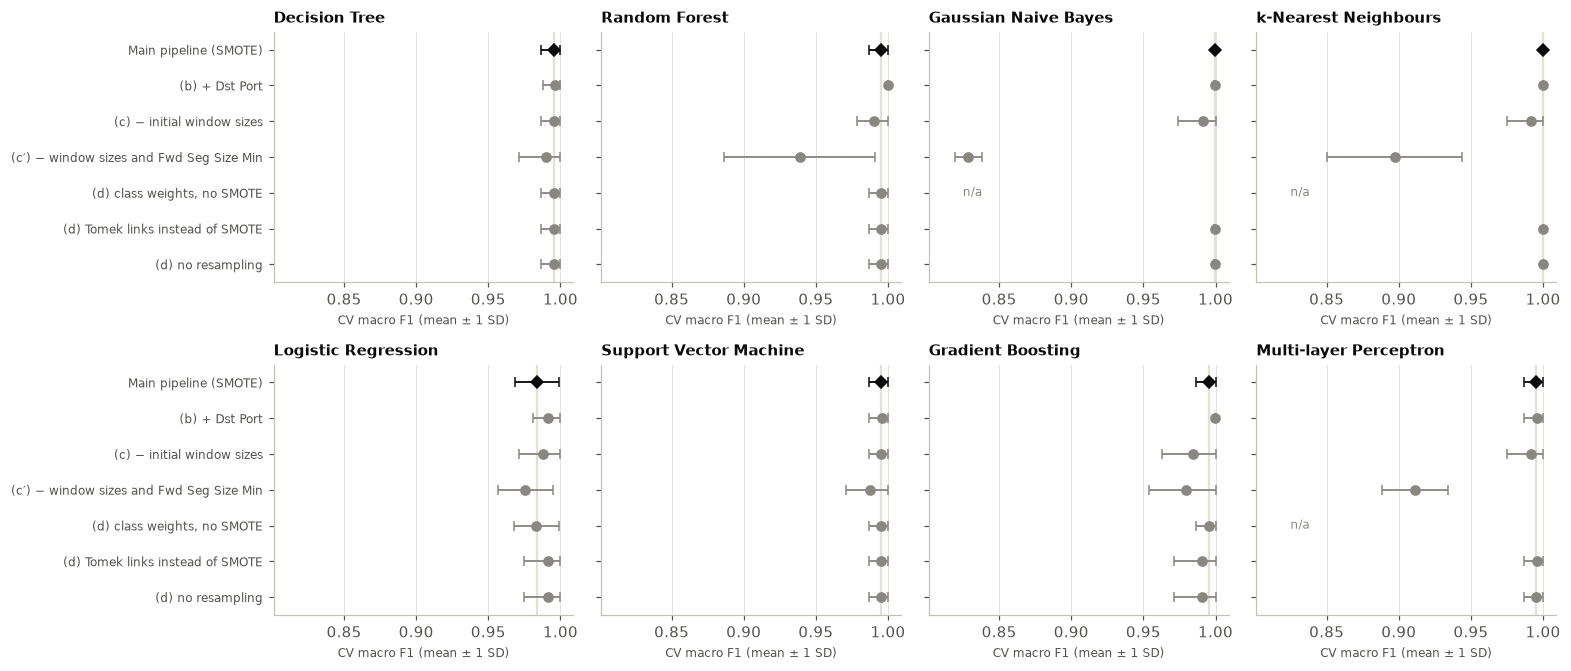

In [11]:
variant_labels = {
    "main": "Main pipeline (SMOTE)", "with_dst_port": "(b) + Dst Port",
    "no_window_sizes": "(c) − initial window sizes",
    "no_host_fingerprint": "(c′) − window sizes and Fwd Seg Size Min",
    "class_weight": "(d) class weights, no SMOTE", "tomek_links": "(d) Tomek links instead of SMOTE",
    "no_resampling": "(d) no resampling",
}


def run_ablation():
    rows = []
    for name, run in runs.items():
        for variant in variant_labels:
            if variant == "class_weight" and not models.supports_class_weight(name):
                rows.append({"model": name, "variant": variant,
                             **{f"{m}_{s}": np.nan for m in models.scorers() for s in ("mean", "std")}})
                continue
            # Ablate the setting I report (chosen by macro F1 in (i)), not the search's weighted-F1 refit.
            pipeline, X_variant = evaluation.variant_pipeline(run, X_train, variant,
                                                              params=macro_selection.loc[name, "params"])
            rows.append({"model": name, "variant": variant, **evaluation.cross_validated(pipeline, X_variant, y_train)})
    return pd.DataFrame(rows)


ablation = models.cached("ablation_eight_models_macro_selected", run_ablation, X_train)
ablation.round(6).to_csv(config.TABLES_DIR / "5_5_ablation_cv.csv", index=False)
fig = plotting.plot_ablation(ablation, variant_labels)
plotting.save_figure(fig, "5_5_ablation_cv_macro_f1")
(ablation.pivot(index="variant", columns="model", values="f1_macro_mean")
         .reindex(index=variant_labels, columns=models.MODEL_NAMES).round(4))

In [12]:
# Why do Tomek links change so little? I count the Tomek links (cross-class nearest-neighbour pairs) they remove.
from imblearn.under_sampling import TomekLinks

scaled_train = features.build_preprocessor(X_train).fit_transform(X_train)
_, y_tomek = TomekLinks(sampling_strategy="auto").fit_resample(scaled_train, y_train)
tomek_removed = len(y_train) - len(y_tomek)
print(f"Tomek links remove {tomek_removed} of {len(y_train):,} training flows")

Tomek links remove 2 of 60,000 training flows


**(iv) Correlation-based feature selection (Week 5 lab).** Inside the pipeline, a feature is kept only if its Spearman
|rho| with every feature kept before it is below the threshold (the lab's 0.7, and 0.95).

In [13]:
def run_feature_selection():
    rows = []
    for name, run in runs.items():
        for threshold in config.CORRELATION_THRESHOLDS:
            pipeline, X_variant = evaluation.variant_pipeline(run, X_train, f"corr_filter_{threshold:.2f}",
                                                              params=macro_selection.loc[name, "params"])
            start = time.perf_counter()
            scores = evaluation.cross_validated(pipeline, X_variant, y_train)
            rows.append({"model": name, "threshold": threshold, **scores, "cv_seconds": time.perf_counter() - start})
    return pd.DataFrame(rows)


selection = models.cached("feature_selection_ablation_macro_selected", run_feature_selection, X_train)
kept_counts = {t: len(features.CorrelationFilter(t).fit(eda.numeric_model_features(X_train)).kept_columns_)
               for t in config.CORRELATION_THRESHOLDS}
main_cv = ablation.query("variant == 'main'").set_index("model")
selection["numeric features kept"] = selection["threshold"].map(kept_counts)
selection["main macro F1"] = selection["model"].map(main_cv["f1_macro_mean"])
selection["main SD"] = selection["model"].map(main_cv["f1_macro_std"])
selection["change in macro F1"] = selection["f1_macro_mean"] - selection["main macro F1"]
selection["within 1 SD of main"] = selection["change in macro F1"] >= -selection["main SD"]
selection.round(6).to_csv(config.TABLES_DIR / "5_5_feature_selection.csv", index=False)
n_numeric = eda.numeric_model_features(X_train).shape[1]
held = {t: selection.query("threshold == @t")["within 1 SD of main"].sum() for t in config.CORRELATION_THRESHOLDS}
print(f"Numeric features kept of {n_numeric}: {kept_counts}; models within 1 SD of main: {held}")
selection.pivot(index="model", columns="threshold", values="change in macro F1").reindex(models.MODEL_NAMES).round(4)

Numeric features kept of 66: {0.7: 16, 0.95: 39}; models within 1 SD of main: {0.7: np.int64(0), 0.95: np.int64(8)}


threshold,0.70,0.95
model,,
Decision Tree,-0.0840,0.0044
Random Forest,-0.0886,0.0000
Gaussian Naive Bayes,-0.1390,0.0000
k-Nearest Neighbours,-0.1135,0.0000
Logistic Regression,-0.0755,0.0001
Support Vector Machine,-0.0884,-0.0000
Gradient Boosting,-0.1004,0.0000
Multi-layer Perceptron,-0.0938,0.0001


### Step 6: Validation

**(a) Without de-duplication.** Proportional sampling and the same 80/20 split on the cleaned but not de-duplicated
rows: how many test flows already occur in training, and what a Random Forest would score.

In [14]:
cleaned_rows = data.build_cleaned_rows()
naive_split = data.split_sample(data.stratified_sample(cleaned_rows, floor=0))  # floor 0 = purely proportional
del cleaned_rows
overlap = data.train_test_overlap(naive_split)
naive_model, _ = evaluation.variant_pipeline(runs[models.FOREST], naive_split.X_train, "no_resampling")
naive_model, _ = evaluation.fit_timed(naive_model, naive_split.X_train, naive_split.y_train)
naive_scores = evaluation.score_predictions(naive_split.y_test, naive_model.predict(naive_split.X_test))
naive_table = pd.DataFrame({"naive test flows": naive_split.y_test.value_counts(),
                            "share already in training set": overlap})
naive_table.round(6).to_csv(config.TABLES_DIR / "5_6_naive_overlap.csv")
print("Random Forest on the naive split:", {k: round(v, 5) for k, v in naive_scores.items()})
naive_table.round(4)

Random Forest on the naive split: {'accuracy': 1.0, 'f1_weighted': 1.0, 'f1_macro': 1.0, 'precision_macro': 1.0, 'recall_macro': 1.0, 'recall_ftp': 1.0}


,naive test flows,share already in training set
Benign,9531,0.1236
FTP-BruteForce,2776,0.9996
SSH-Bruteforce,2693,0.5095


**(b) Cross-validation versus test:** CV mean ± SD against the test score and its 95% bootstrap interval.

cv_mean                          test           \
metric                 accuracy f1_macro f1_weighted accuracy f1_macro   
model                                                                    
Decision Tree           0.99985  0.99030     0.99985  0.99987  0.99983   
Random Forest           0.99993  0.99549     0.99993  0.99993  0.98244   
Gaussian Naive Bayes    0.99963  0.99952     0.99963  0.99980  0.99974   
k-Nearest Neighbours    0.99998  0.99998     0.99998  0.99993  0.99991   
Logistic Regression     0.99985  0.97928     0.99985  0.99980  0.96655   
Support Vector Machine  0.99992  0.99547     0.99992  0.99987  0.98236   
Gradient Boosting       0.99995  0.99551     0.99995  1.00000  1.00000   
Multi-layer Perceptron  0.99988  0.98765     0.99989  0.99993  0.98244   

                                    
metric                 f1_weighted  
model                               
Decision Tree              0.99987  
Random Forest              0.99994  
Gaussian Naive Bayes       0.99980  
k-Nearest Neighbours       0.99993  
Logistic Regression        0.99981  
Support Vector Machine     0.99987  
Gradient Boosting          1.00000  
Multi-layer Perceptron     0.99994

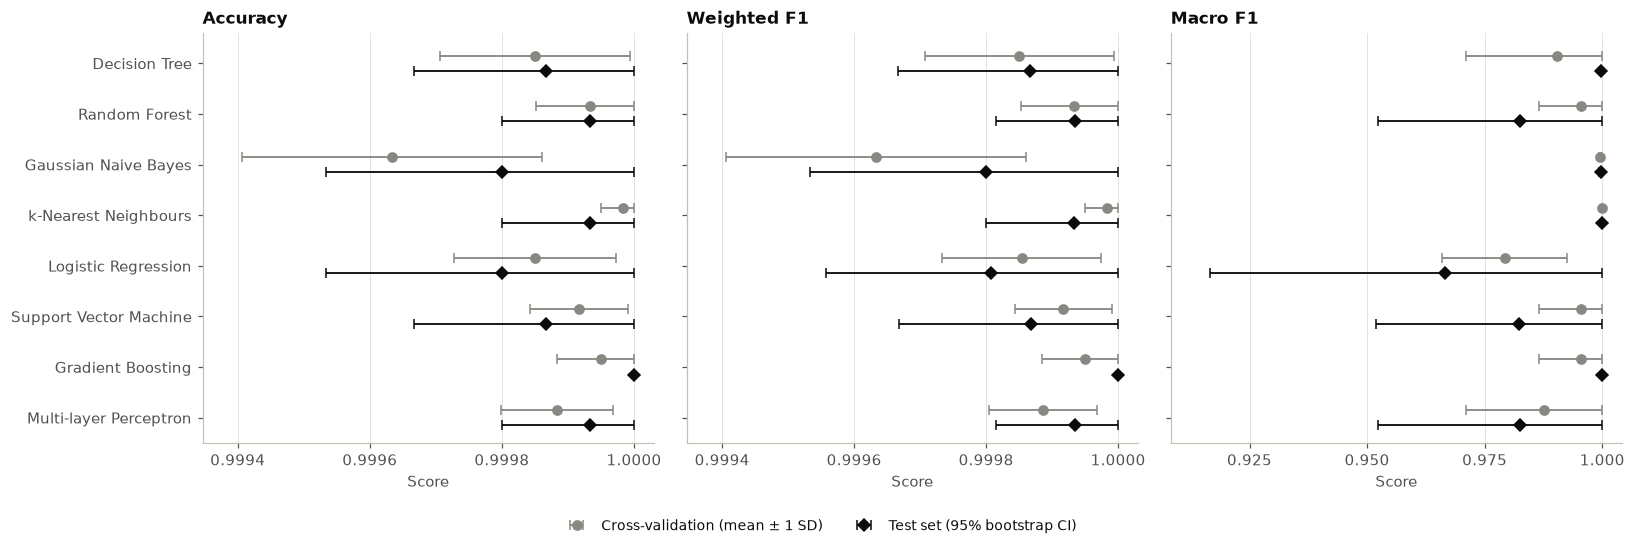

In [15]:
rows = []
for name, run in runs.items():
    res, best = run.search.cv_results_, run.search.best_index_
    for metric in ("accuracy", "f1_weighted", "f1_macro"):
        low, high = evaluation.bootstrap_interval(y_test, predictions[name], metric)
        rows.append({"model": name, "metric": metric,
                     "cv_mean": res[f"mean_test_{metric}"][best], "cv_std": res[f"std_test_{metric}"][best],
                     "test": test_results.loc[name, metric], "test_low": low, "test_high": high})
cv_vs_test = pd.DataFrame(rows)
cv_vs_test.round(6).to_csv(config.TABLES_DIR / "5_6_cv_vs_test.csv", index=False)
fig = plotting.plot_cv_vs_test(cv_vs_test, {"accuracy": "Accuracy", "f1_weighted": "Weighted F1", "f1_macro": "Macro F1"})
plotting.save_figure(fig, "5_6_cv_vs_test")
cv_vs_test.pivot(index="model", columns="metric", values=["cv_mean", "test"]).reindex(models.MODEL_NAMES).round(5)

**(c) Learning curves (Week 2: under- and over-fitting)**, 30% to 100% of a training fold.

,train − validation gap at full size,validation gain over the last step
Decision Tree,0.0045,0.0051
Random Forest,0.0045,0.0000
Gaussian Naive Bayes,0.0000,0.0000
k-Nearest Neighbours,0.0000,0.0000
Logistic Regression,0.0059,0.0006
Support Vector Machine,0.0045,0.0000
Gradient Boosting,0.0023,0.0000
Multi-layer Perceptron,0.0001,0.0038


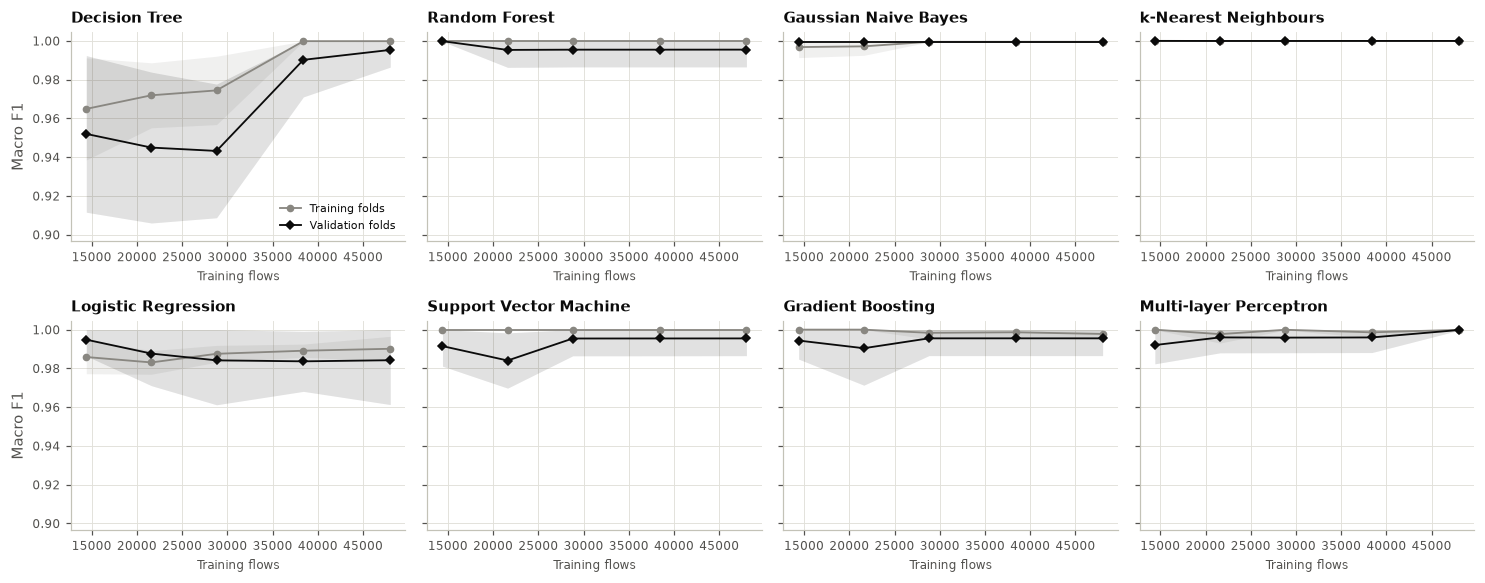

In [16]:
curves = models.cached(
    "learning_curves_eight_models",
    lambda: {name: evaluation.learning_curve_table(clone(macro_models[name]), X_train, y_train)
             for name in models.MODEL_NAMES},
    X_train)
fig = plotting.plot_learning_curves(curves)
plotting.save_figure(fig, "5_6_learning_curves")
pd.concat(curves, names=["model", "row"]).reset_index(level="row", drop=True).round(6).to_csv(
    config.TABLES_DIR / "5_6_learning_curves.csv")
final_gap = {n: c["train_mean"].iloc[-1] - c["valid_mean"].iloc[-1] for n, c in curves.items()}
gain_last_step = {n: c["valid_mean"].iloc[-1] - c["valid_mean"].iloc[-2] for n, c in curves.items()}
pd.DataFrame({"train − validation gap at full size": final_gap,
              "validation gain over the last step": gain_last_step}).round(4)

**(d) Predicting on new data: 15 February 2018 (Week 6 lab).** Another day of the dataset, cleaned the same way, with
flows already in my sample removed: 20,000 benign flows and 5,000 of each of two DoS attacks the models never saw.

,Benign,DoS attacks-GoldenEye,DoS attacks-Slowloris
raw,996077,41508,10990
unique,743449,41406,9859
removed_as_known,6515,0,0
sampled,20000,5000,5000


,benign false alarms,benign ci_low,benign ci_high,DoS attacks-GoldenEye flagged,DoS attacks-GoldenEye as SSH,DoS attacks-Slowloris flagged,DoS attacks-Slowloris as SSH
model,,,,,,,
Decision Tree,0.0001,0.0001,0.0004,0.4638,0.4638,0.0092,0.0092
Random Forest,0.0000,0.0000,0.0002,0.0000,0.0000,0.0000,0.0000
Gaussian Naive Bayes,0.0000,0.0000,0.0002,0.0000,0.0000,0.0000,0.0000
k-Nearest Neighbours,0.0001,0.0000,0.0004,0.7758,0.7758,0.0004,0.0002
Logistic Regression,0.0000,0.0000,0.0002,0.0000,0.0000,0.0002,0.0002
Support Vector Machine,0.0001,0.0000,0.0004,0.3206,0.3206,0.0106,0.0106
Gradient Boosting,0.0000,0.0000,0.0003,0.0286,0.0286,0.0218,0.0218
Multi-layer Perceptron,0.0001,0.0000,0.0004,0.2100,0.2100,0.0000,0.0000


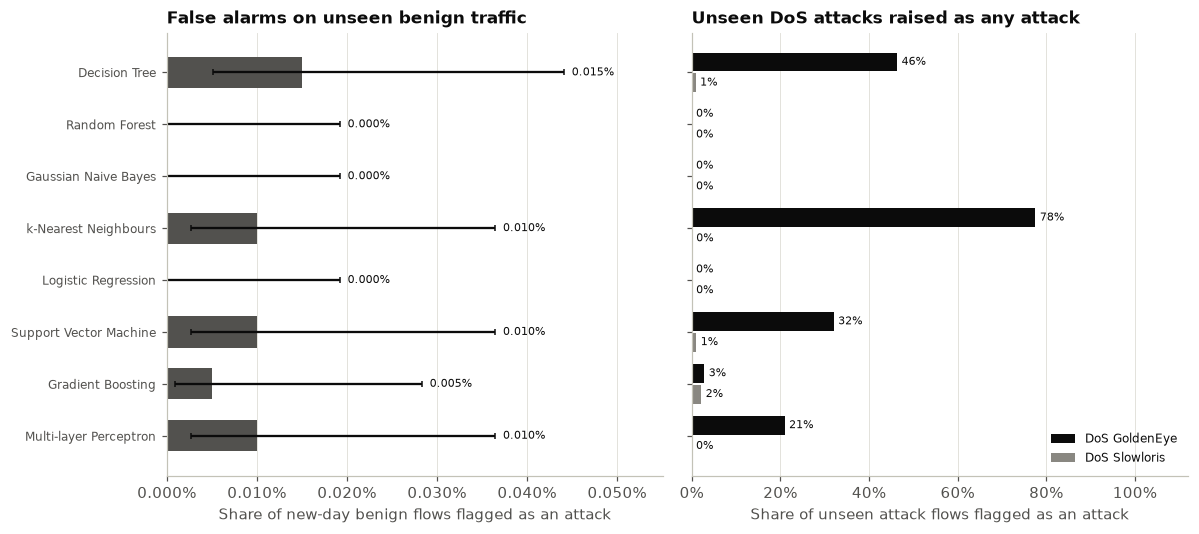

In [17]:
unseen, unseen_stages = data.load_or_build_unseen_day(sample)
display(unseen_stages)
unseen_rows, unseen_reports = [], {}
for name in models.MODEL_NAMES:
    report = unseen_reports[name] = evaluation.unseen_day_report(macro_models[name], unseen)
    benign = report.loc["Benign"]
    false_alarms = int(round((1 - benign["predicted Benign"]) * benign["flows"]))
    interval = evaluation.wilson_interval(false_alarms, int(benign["flows"]))
    row = {"model": name, "benign false alarms": interval["rate"], "benign ci_low": interval["ci_low"],
           "benign ci_high": interval["ci_high"]}
    for attack in [label for label in report.index if label != "Benign"]:
        row[f"{attack} flagged"] = 1 - report.loc[attack, "predicted Benign"]
        row[f"{attack} as SSH"] = report.loc[attack, "predicted SSH-Bruteforce"]
    unseen_rows.append(row)
unseen_table = pd.DataFrame(unseen_rows).set_index("model")
unseen_table.round(6).to_csv(config.TABLES_DIR / "5_6_unseen_day.csv")
pd.concat(unseen_reports, names=["model"]).round(6).to_csv(config.TABLES_DIR / "5_6_unseen_day_by_class.csv")
fig = plotting.plot_unseen_day(unseen_table[[c for c in unseen_table.columns if not c.endswith(" as SSH")]])
plotting.save_figure(fig, "5_6_unseen_day")
unseen_table.round(4)

In [18]:
# Do the unseen DoS flows that a model flags carry the attacking hosts' initial TCP window (26,883 bytes)?
dos = unseen[unseen[config.LABEL_COL] != "Benign"]
has_fingerprint = dos["Init Fwd Win Byts"].eq(26883).to_numpy()
dos_fingerprint = dos["Init Fwd Win Byts"].eq(26883).groupby(dos[config.LABEL_COL]).mean()
flag_rows = []
for name in models.MODEL_NAMES:
    flagged = macro_models[name].predict(dos.drop(columns=[config.LABEL_COL])) != "Benign"
    flag_rows.append({"model": name, "DoS flows flagged": int(flagged.sum()),
                      "share of flagged with fingerprint": has_fingerprint[flagged].mean() if flagged.any() else np.nan,
                      "share of fingerprinted flagged": flagged[has_fingerprint].mean(),
                      "share of non-fingerprinted flagged": flagged[~has_fingerprint].mean()})
dos_flags = pd.DataFrame(flag_rows).set_index("model")
dos_flags.round(6).to_csv(config.TABLES_DIR / "5_6_unseen_dos_fingerprint.csv")
print("Share of unseen DoS flows with the 26,883-byte window:", dos_fingerprint.round(4).to_dict())
dos_flags.round(4)

Share of unseen DoS flows with the 26,883-byte window: {'DoS attacks-GoldenEye': 0.6558, 'DoS attacks-Slowloris': 0.7244}


,DoS flows flagged,share of flagged with fingerprint,share of fingerprinted flagged,share of non-fingerprinted flagged
model,,,,
Decision Tree,2365,0.9805,0.3360,0.0148
Random Forest,0,NaN,0.0000,0.0000
Gaussian Naive Bayes,0,NaN,0.0000,0.0000
k-Nearest Neighbours,3881,0.7253,0.4079,0.3440
Logistic Regression,1,0.0000,0.0000,0.0003
Support Vector Machine,1656,0.0000,0.0000,0.5344
Gradient Boosting,252,0.6270,0.0229,0.0303
Multi-layer Perceptron,1050,0.0000,0.0000,0.3388


**Does the tree need the attackers' TCP settings to raise those alarms?** I refit it without them (same tuned
settings) and score the same new-day flows. A diagnostic for RQ2, not a new model choice.

In [19]:
no_fp_tree, X_no_fp = evaluation.variant_pipeline(runs[models.TREE], X_train, "no_host_fingerprint",
                                                  params=macro_selection.loc[models.TREE, "params"])
no_fp_tree, _ = evaluation.fit_timed(no_fp_tree, X_no_fp, y_train)
no_fp_report = evaluation.unseen_day_report(no_fp_tree, unseen.drop(columns=evaluation.HOST_FINGERPRINT_COLS))
no_fp_report.round(6).to_csv(config.TABLES_DIR / "5_6_unseen_day_tree_without_fingerprint.csv")
X_test_no_fp = X_test.drop(columns=evaluation.HOST_FINGERPRINT_COLS)
no_fp_test_errors = int((no_fp_tree.predict(X_test_no_fp) != y_test.to_numpy()).sum())
no_fp_flagged = {label: 1 - no_fp_report.loc[label, "predicted Benign"] for label in no_fp_report.index if label != "Benign"}
print(f"Tree without fingerprint columns: {no_fp_test_errors} test errors; unseen DoS flagged "
      f"{({k: round(v, 4) for k, v in no_fp_flagged.items()})}")
no_fp_report.round(4)

Tree without fingerprint columns: 2 test errors; unseen DoS flagged {'DoS attacks-GoldenEye': np.float64(0.0), 'DoS attacks-Slowloris': np.float64(0.002)}


col_0,flows,predicted Benign,predicted FTP-BruteForce,predicted SSH-Bruteforce
true label,,,,
Benign,20000,1.000,0.0,0.000
DoS attacks-GoldenEye,5000,1.000,0.0,0.000
DoS attacks-Slowloris,5000,0.998,0.0,0.002


### Step 7: Comparative Analysis of Multiple Algorithms

The eight algorithms on the same folds and metrics, with the macro-selected settings, and the selection rule applied.

In [20]:
ms = macro_selection
ab = ablation.set_index(["model", "variant"])["f1_macro_mean"]
fingerprint_drop = {m: ab[(m, "main")] - ab[(m, "no_host_fingerprint")] for m in models.MODEL_NAMES}

cv_best = ms["cv_f1_macro (macro-selected)"]
leader = cv_best.idxmax()
tied = cv_best[cv_best >= cv_best[leader] - ms.loc[leader, "cv_f1_macro_std"]].index.tolist()
final_name = ms.loc[tied, "inference_ms_per_1000"].idxmin()
print(f"Highest CV macro F1: {leader}; tied within 1 SD: {tied}; final model (fastest of the tied): {final_name}")

comparison = evaluation.final_comparison_table(ms, fingerprint_drop, models.MODEL_NAMES)
comparison.to_csv(config.TABLES_DIR / "5_7_final_comparison.csv")
comparison

Highest CV macro F1: k-Nearest Neighbours; tied within 1 SD: ['k-Nearest Neighbours']; final model (fastest of the tied): k-Nearest Neighbours


,CV macro F1,Test accuracy,Test macro F1 [95% CI],"Test errors (of 15,000)",Test FTP recall,Training time (s),"Inference (ms / 1,000 flows)",Macro F1 drop without host fingerprint
Decision Tree,0.99534 ± 0.00890,0.99993,"0.9999 [0.9997, 1.0000]",1,1.0,0.45,0.56,0.0051
Random Forest,0.99549 ± 0.00892,0.99993,"0.9824 [0.9523, 1.0000]",1,1.0,3.71,2.92,0.0568
Gaussian Naive Bayes,0.99952 ± 0.00029,0.99980,"0.9997 [0.9994, 1.0000]",3,1.0,0.28,1.09,0.1709
k-Nearest Neighbours,0.99998 ± 0.00004,0.99993,"0.9999 [0.9997, 1.0000]",1,1.0,0.27,30.61,0.1028
Logistic Regression,0.98368 ± 0.01551,0.99987,"0.9824 [0.9520, 1.0000]",2,1.0,0.64,1.15,0.0080
Support Vector Machine,0.99547 ± 0.00891,0.99987,"0.9824 [0.9519, 1.0000]",2,1.0,0.65,2.13,0.0079
Gradient Boosting,0.99551 ± 0.00893,1.00000,"1.0000 [1.0000, 1.0000]",0,1.0,3.15,8.03,0.0163
Multi-layer Perceptron,0.99534 ± 0.00884,0.99980,"0.9823 [0.9518, 1.0000]",3,1.0,2.53,0.83,0.0840


--- k-Nearest Neighbours (final model) ---
                precision    recall  f1-score   support

        Benign     1.0000    0.9999    1.0000     12715
FTP-BruteForce     1.0000    1.0000    1.0000         9
SSH-Bruteforce     0.9996    1.0000    0.9998      2276

      accuracy                         0.9999     15000
     macro avg     0.9999    1.0000    0.9999     15000
  weighted avg     0.9999    0.9999    0.9999     15000



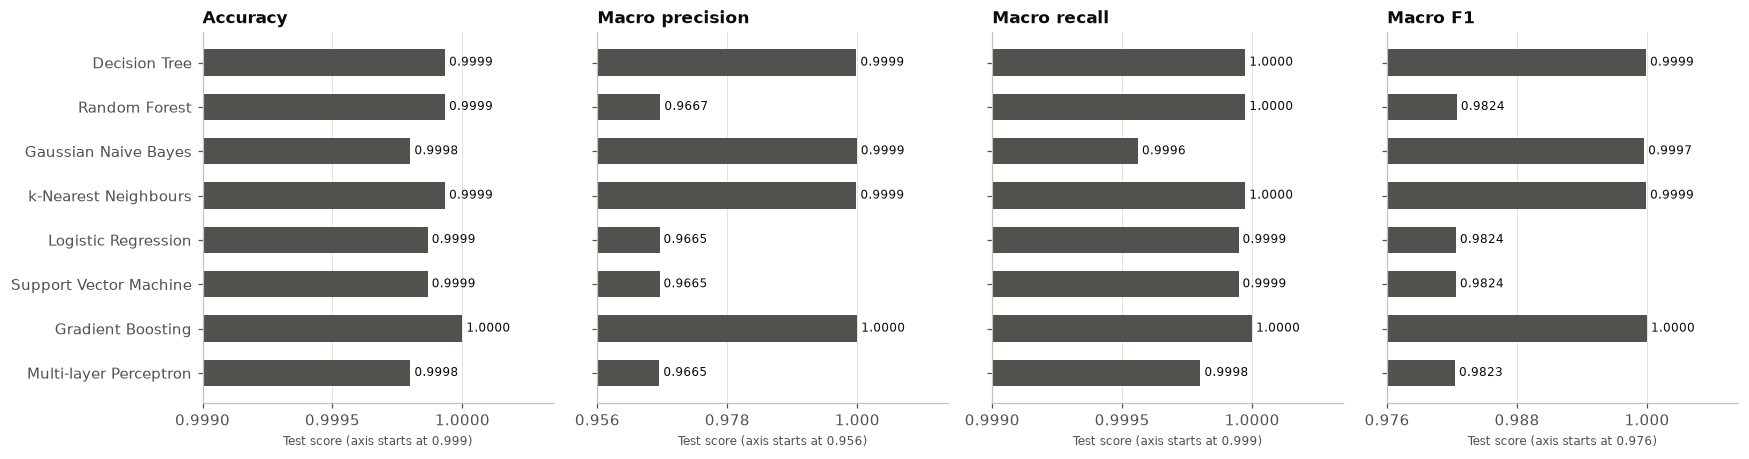

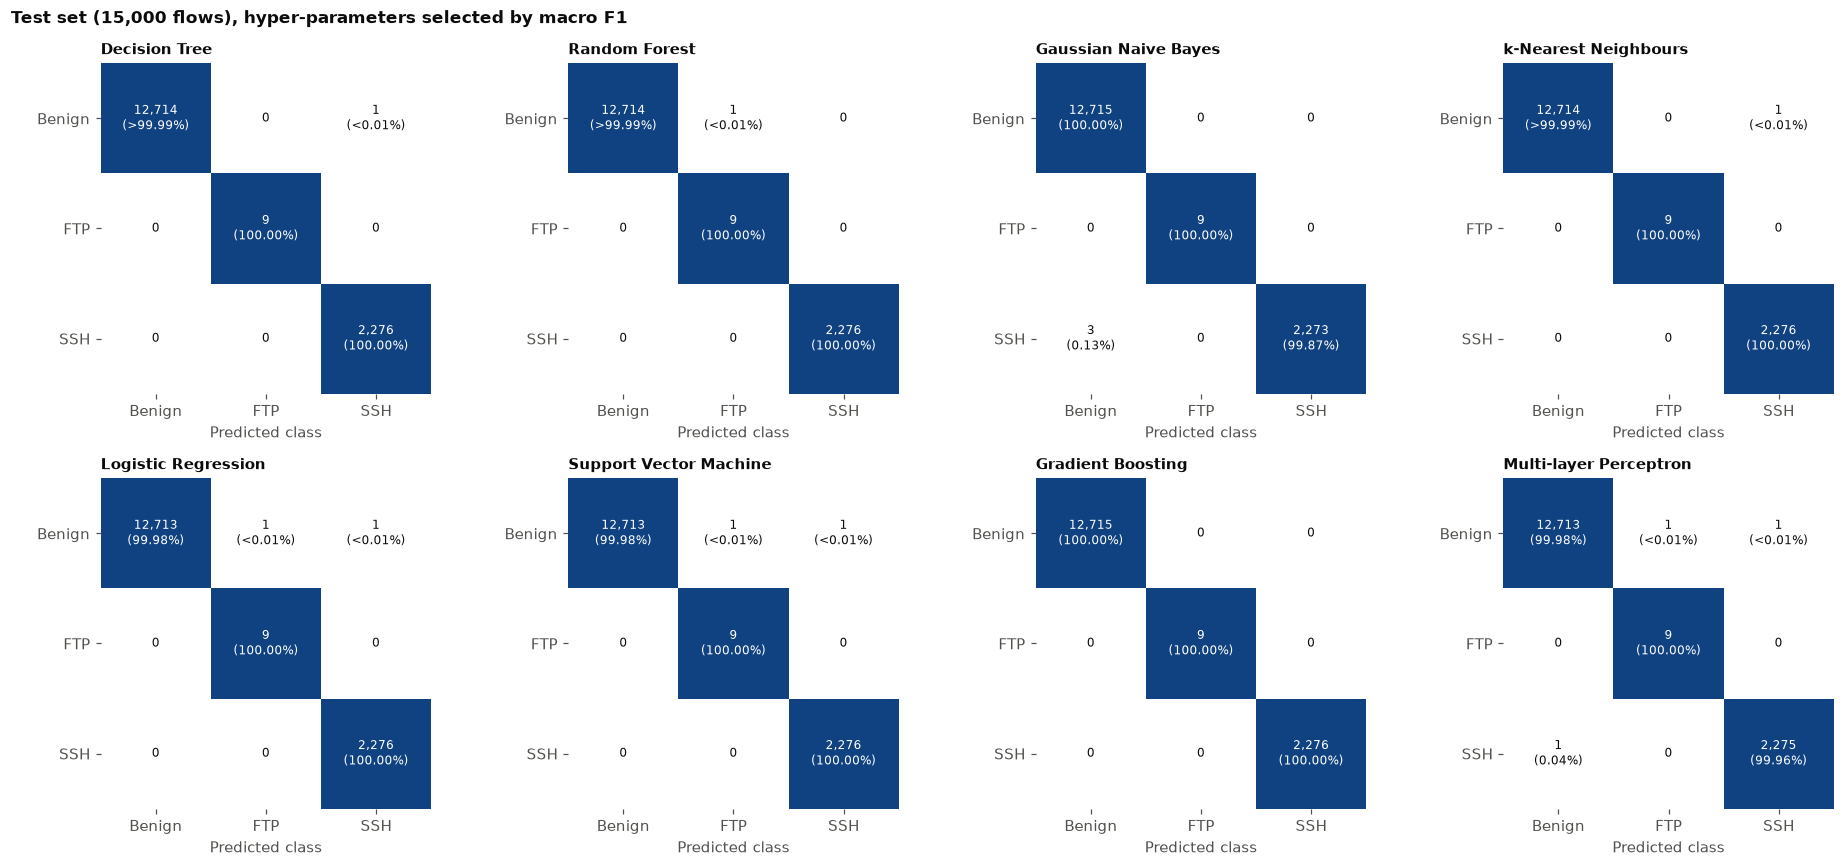

In [21]:
macro_metrics = ms.rename(columns={"test_accuracy": "accuracy", "test_precision_macro": "precision_macro",
                                   "test_recall_macro": "recall_macro", "test_f1_macro": "f1_macro"})
fig = plotting.plot_metric_bars(macro_metrics, metric_labels)
plotting.save_figure(fig, "5_7_comparison_bar_chart")
fig = plotting.plot_confusion_matrices({n: (y_test.to_numpy(), p) for n, p in macro_predictions.items()},
                                       "Test set (15,000 flows), hyper-parameters selected by macro F1")
plotting.save_figure(fig, "5_7_confusion_matrices_test_macro_selected")
print(f"--- {final_name} (final model) ---")
print(classification_report(y_test, macro_predictions[final_name], digits=4, zero_division=0))

**What the models learned.** The Decision Tree drawn with `plot_tree` (Week 4 lab) and its rules in raw units; the
Random Forest's impurity and permutation importance.

if Fwd Seg Size Min <= 30.00:
|   → Benign
else (Fwd Seg Size Min > 30.00):
|   if Bwd Pkt Len Max <= 808.00:
|   |   if Bwd Pkts/s <= 14,693.26:
|   |   |   if Flow Pkts/s <= 8,903.76:
|   |   |   |   → Benign (subtree truncated)
|   |   |   else (Flow Pkts/s > 8,903.76):
|   |   |   |   → SSH-Bruteforce (subtree truncated)
|   |   else (Bwd Pkts/s > 14,693.26):
|   |   |   if Init Fwd Win Byts <= 17,537.50:
|   |   |   |   → Benign (subtree truncated)
|   |   |   else (Init Fwd Win Byts > 17,537.50):
|   |   |   |   → FTP-BruteForce
|   else (Bwd Pkt Len Max > 808.00):
|   |   → SSH-Bruteforce


,min,50%,max
Label,,,
Benign,0.0,20.0,40.0
FTP-BruteForce,40.0,40.0,40.0
SSH-Bruteforce,32.0,32.0,32.0


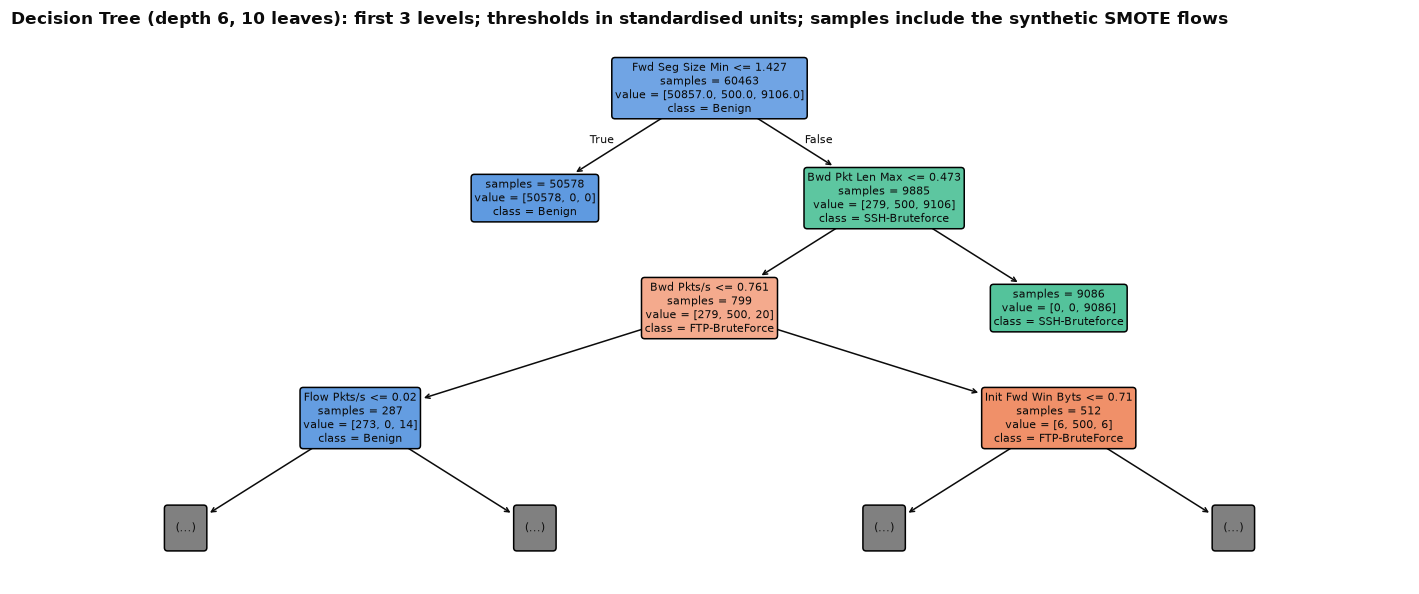

In [22]:
tree_model = macro_models[models.TREE]
fig = plotting.plot_decision_tree(tree_model, max_depth=3)
plotting.save_figure(fig, "5_7_decision_tree")
tree_rules = evaluation.tree_rules_in_original_units(tree_model, max_depth=4)
(config.TABLES_DIR / "5_7_decision_tree_rules.txt").write_text(tree_rules + "\n")
print(tree_rules)
X_train.groupby(y_train, observed=True)["Fwd Seg Size Min"].describe()[["min", "50%", "max"]]

,impurity_importance,permutation_drop_f1_macro,permutation_std
Fwd Seg Size Min,0.1281,0.0110,0.0108
Init Fwd Win Byts,0.0756,0.0000,0.0000
Fwd Header Len,0.0718,-0.0035,0.0070
TotLen Fwd Pkts,0.0658,-0.0070,0.0086
Bwd Header Len,0.0656,0.0001,0.0000
Fwd Act Data Pkts,0.0656,0.0000,0.0000
Subflow Fwd Pkts,0.0597,-0.0140,0.0070
Tot Fwd Pkts,0.0515,0.0000,0.0000
Subflow Bwd Pkts,0.0441,0.0000,0.0000
Subflow Fwd Byts,0.0391,0.0000,0.0000


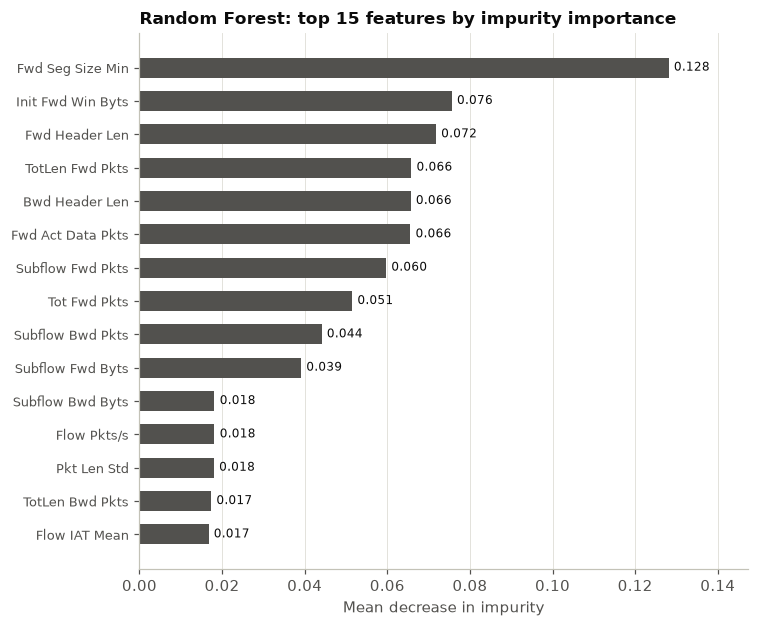

In [23]:
importance = evaluation.importance_table(macro_models[models.FOREST], X_test, y_test, top=15)
importance.round(6).to_csv(config.TABLES_DIR / "5_7_random_forest_importance.csv")
fig = plotting.plot_importance(importance["impurity_importance"], "Random Forest: top 15 features by impurity importance",
                               "Mean decrease in impurity")
plotting.save_figure(fig, "5_7_random_forest_importance")
importance.round(4)

**Strengths and weaknesses** on this problem: measured numbers beside the property that explains them.

In [24]:
notes = {
    models.TREE: "readable threshold rules; one tree can over-fit, controlled here by depth and leaf size",
    models.FOREST: "averaging lowers variance; slower and harder to read than one tree",
    models.NAIVE_BAYES: "simple probabilistic model; its independence assumption is violated by the redundant features",
    models.KNN: "no training; stores all flows, so inference is the slowest and depends on near-copies in training",
    models.LOGREG: "linear boundary; needs scaling and the symlog transform to cope with heavy tails",
    models.SVM: "maximum-margin boundary; needs scaling, training cost grows quickly with data size",
    models.BOOSTING: "corrects errors tree by tree; strong on tabular data, slower inference than one tree",
    models.MLP: "learns non-linear features; needs scaling and more tuning, least interpretable",
}
# Claims about speed come from this run's measurements, not from what the algorithm usually does.
notes[ms["fit_seconds"].idxmin()] += "; fastest to train in this run"
strengths = pd.DataFrame({
    "CV macro F1": cv_best.round(5), "test errors": ms["test_errors"],
    "inference ms / 1,000": ms["inference_ms_per_1000"].round(2),
    "drop without host fingerprint": pd.Series(fingerprint_drop).round(4),
    "property that explains the result": pd.Series(notes),
}).reindex(models.MODEL_NAMES)
strengths.to_csv(config.TABLES_DIR / "5_7_strengths_weaknesses.csv")
strengths

,CV macro F1,test errors,"inference ms / 1,000",drop without host fingerprint,property that explains the result
Decision Tree,0.99534,1,0.56,0.0051,readable threshold rules; one tree can over-fi...
Random Forest,0.99549,1,2.92,0.0568,averaging lowers variance; slower and harder t...
Gaussian Naive Bayes,0.99952,3,1.09,0.1709,simple probabilistic model; its independence a...
k-Nearest Neighbours,0.99998,1,30.61,0.1028,"no training; stores all flows, so inference is..."
Logistic Regression,0.98368,2,1.15,0.0080,linear boundary; needs scaling and the symlog ...
Support Vector Machine,0.99547,2,2.13,0.0079,"maximum-margin boundary; needs scaling, traini..."
Gradient Boosting,0.99551,0,8.03,0.0163,corrects errors tree by tree; strong on tabula...
Multi-layer Perceptron,0.99534,3,0.83,0.0840,learns non-linear features; needs scaling and ...


**Deployment recommendation** (a separate question from the selection rule): among models within 0.01 macro F1 of the
leader that lose less than 0.01 without the attackers' TCP settings, the fastest.

In [25]:
robust_candidates = [m for m in models.MODEL_NAMES
                     if cv_best[m] >= cv_best[leader] - 0.01 and fingerprint_drop[m] < 0.01]
recommended = ms.loc[robust_candidates, "inference_ms_per_1000"].idxmin() if robust_candidates else final_name
print("Robust candidates:", robust_candidates, "-> recommended for deployment:", recommended)

# predict.py serves the recommended model under a fixed file name; stop if the recommendation changes.
assert recommended == models.TREE, "update predict.FINAL_MODEL_PATH: the recommended model is no longer the Decision Tree"
predict.FINAL_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(macro_models[recommended], predict.FINAL_MODEL_PATH)
print(f"Saved {predict.FINAL_MODEL_PATH.relative_to(config.PROJECT_ROOT)} for `python -m nids.predict`")

Robust candidates: ['Decision Tree', 'Support Vector Machine'] -> recommended for deployment: Decision Tree
Saved models/final_decision_tree.joblib for `python -m nids.predict`


## **Save the numbers quoted in the report** (`reports/numbers.json`)

In [26]:
def listing(names):
    # "A", "A and B", "A, B and C": model names as the report lists them.
    names = list(names)
    return "" if not names else names[0] if len(names) == 1 else ", ".join(names[:-1]) + " and " + names[-1]


def pct(x: float, digits: int = 1) -> str:
    return f"{x:.{digits}%}"


def delta(model, variant):
    return ab[(model, variant)] - ab[(model, "main")]


r, ut = test_results, unseen_table
ab_sd = ablation.set_index(["model", "variant"])["f1_macro_std"]
ftp_found = {m: int(round(r.loc[m, "recall_ftp"] * 9)) for m in models.MODEL_NAMES}
port_gain = [m for m in models.MODEL_NAMES if delta(m, "with_dst_port") > ab_sd[(m, "main")]]
class_weight_models = [m for m in models.MODEL_NAMES if models.supports_class_weight(m)]
class_weight_delta = {m: delta(m, "class_weight") for m in class_weight_models}
reliant = sorted((m for m in models.MODEL_NAMES if fingerprint_drop[m] >= 0.01), key=lambda m: -fingerprint_drop[m])
not_reliant = [m for m in models.MODEL_NAMES if m not in reliant]
no_res = {m: delta(m, "no_resampling") for m in models.MODEL_NAMES}
tomek = {m: delta(m, "tomek_links") for m in models.MODEL_NAMES}
smote_helped = [m for m in models.MODEL_NAMES if no_res[m] < -ms.loc[m, "cv_f1_macro_std"]]
largest_gap = max(final_gap, key=final_gap.get)
sel = selection.set_index(["threshold", "model"])
worst_drop = {t: sel.loc[t]["change in macro F1"].min() for t in config.CORRELATION_THRESHOLDS}
worst_model = {t: sel.loc[t]["change in macro F1"].idxmin() for t in config.CORRELATION_THRESHOLDS}

In [27]:
GE, SL = "DoS attacks-GoldenEye", "DoS attacks-Slowloris"
fa_rec, fa_final = ut.loc[recommended], ut.loc[final_name]
fa_count = (ut["benign false alarms"] * int(unseen_stages.loc["sampled", "Benign"])).round().astype(int)
unseen_missed_rec = 1 - min(ut.loc[recommended, f"{GE} flagged"], ut.loc[recommended, f"{SL} flagged"])

report_numbers.record(
    test_errors_min=f"{int(r['test_errors'].min())}", test_errors_max=f"{int(r['test_errors'].max())}",
    test_macro_min=f"{r['f1_macro'].min():.4f}", test_macro_max=f"{r['f1_macro'].max():.4f}",
    ftp_found_min=f"{min(ftp_found.values())}",
    dt_features_used=f"{dt_used}", dt_top3_share=pct(dt_top3_share, 1), rf_top3_share=pct(rf_top3_share, 1),
    port_gain_models=f"{len(port_gain)}", fingerprint_reliant=listing(reliant) or "no model",
    fingerprint_not_reliant=listing(not_reliant), fingerprint_reliant_n=f"{len(reliant)}",
    fingerprint_max_drop=f"{fingerprint_drop[reliant[0]]:.4f} ({reliant[0]})" if reliant else "none",
    tree_fingerprint_drop=f"{round(fingerprint_drop[models.TREE], 4) + 0.0:.4f}",
    tomek_removed=f"{tomek_removed}", tomek_range=f"{min(tomek.values()):+.4f} to {max(tomek.values()):+.4f}",
    class_weight_range=f"{min(class_weight_delta.values()):+.4f} to {max(class_weight_delta.values()):+.4f}",
    class_weight_models=listing(class_weight_models),
    smote_helped=listing(smote_helped) or "no model",
    no_resampling_range=f"{min(no_res.values()):+.4f} to {max(no_res.values()):+.4f}",
    knn_k=f"{macro_selection.loc[models.KNN, 'params'].get('model__n_neighbors')}",
    ms_macro_worst=f"{cv_best.idxmin()} ({cv_best.min():.4f})", ms_macro_worst_name=cv_best.idxmin(),
    l1_c=f"{sparse['C']:g}", l1_kept=f"{int(sparse['features_used'])}",
    l1_total=f"{int(sparse['features_used'] + sparse['features_removed'])}",
    l1_macro=f"{sparse['cv_f1_macro_mean']:.4f}", l2_macro=f"{l2_same_c['cv_f1_macro_mean']:.4f}",
    fs_kept_070=f"{kept_counts[0.70]}", fs_kept_095=f"{kept_counts[0.95]}", fs_numeric=f"{n_numeric}",
    fs_held_070=f"{held[0.70]}", fs_held_095=f"{held[0.95]}", fs_drop_models_070=f"{8 - held[0.70]}",
    fs_worst_070=f"{worst_drop[0.70]:+.4f} ({worst_model[0.70]})",
)

{'test_errors_min': '0',
 'test_errors_max': '3',
 'test_macro_min': '0.9666',
 'test_macro_max': '1.0000',
 'ftp_found_min': '9',
 'dt_features_used': '10',
 'dt_top3_share': '99.6%',
 'rf_top3_share': '27.5%',
 'port_gain_models': '0',
 'fingerprint_reliant': 'Gaussian Naive Bayes, k-Nearest Neighbours, Multi-layer Perceptron, Random Forest and Gradient Boosting',
 'fingerprint_not_reliant': 'Decision Tree, Logistic Regression and Support Vector Machine',
 'fingerprint_reliant_n': '5',
 'fingerprint_max_drop': '0.1709 (Gaussian Naive Bayes)',
 'tree_fingerprint_drop': '0.0051',
 'tomek_removed': '2',
 'tomek_range': '-0.0051 to +0.0079',
 'class_weight_range': '-0.0003 to +0.0000',
 'class_weight_models': 'Decision Tree, Random Forest, Logistic Regression, Support Vector Machine and Gradient Boosting',
 'smote_helped': 'no model',
 'no_resampling_range': '-0.0051 to +0.0079',
 'knn_k': '1',
 'ms_macro_worst': 'Logistic Regression (0.9837)',
 'ms_macro_worst_name': 'Logistic Regressio

In [28]:
report_numbers.record(
    naive_ftp_overlap=f"{overlap.get('FTP-BruteForce', float('nan')):.2%}",
    naive_ssh_overlap=f"{overlap.get('SSH-Bruteforce', float('nan')):.1%}",
    naive_rf_macro=f"{naive_scores['f1_macro']:.4f}", lc_largest_gap=f"{final_gap[largest_gap]:.4f} ({largest_gap})",
    final_model=final_name, final_cv_macro=f"{cv_best[final_name]:.5f}", tied_models=listing(tied),
    final_test_macro=f"{ms.loc[final_name, 'test_f1_macro']:.4f}", final_test_errors=f"{ms.loc[final_name, 'test_errors']}",
    final_ms=f"{ms.loc[final_name, 'inference_ms_per_1000']:.2f}",
    recommended_model=recommended, recommended_ms=f"{ms.loc[recommended, 'inference_ms_per_1000']:.2f}",
    recommended_test_errors=f"{ms.loc[recommended, 'test_errors']}",
    recommended_cv_macro=f"{cv_best[recommended]:.5f} ± {ms.loc[recommended, 'cv_f1_macro_std']:.5f}",
    unseen_benign_n=f"{int(unseen_stages.loc['sampled', 'Benign']):,}",
    unseen_removed_known=f"{int(unseen_stages.loc['removed_as_known', 'Benign']):,}",
    unseen_fa_rec=pct(fa_rec["benign false alarms"], 2), unseen_fa_rec_pct=pct(fa_rec["benign false alarms"], 3),
    unseen_fa_rec_ci=f"{pct(fa_rec['benign ci_low'], 3)}–{pct(fa_rec['benign ci_high'], 3)}",
    unseen_fa_final=pct(fa_final["benign false alarms"], 2),
    unseen_fa_min=f"{pct(ut['benign false alarms'].min(), 2)} ({ut['benign false alarms'].idxmin()})",
    unseen_fa_max=f"{pct(ut['benign false alarms'].max(), 2)} ({ut['benign false alarms'].idxmax()})",
    unseen_fa_count_rec=f"{int(fa_count[recommended])}", unseen_fa_count_min=f"{fa_count.min()}",
    unseen_fa_count_max=f"{fa_count.max()}",
    unseen_fewest_fa=listing(m for m in models.MODEL_NAMES if fa_count[m] == fa_count.min()),
    unseen_most_fa=listing(m for m in models.MODEL_NAMES if fa_count[m] == fa_count.max()),
    unseen_ge_flagged_rec=pct(ut.loc[recommended, f"{GE} flagged"], 0),
    unseen_sl_flagged_rec=pct(ut.loc[recommended, f"{SL} flagged"], 0),
    unseen_ge_flagged_knn=pct(ut.loc[models.KNN, f"{GE} flagged"], 0), unseen_missed_rec=pct(unseen_missed_rec, 0),
    unseen_ge_fingerprint=pct(dos_fingerprint.get(GE, 0), 0), unseen_sl_fingerprint=pct(dos_fingerprint.get(SL, 0), 0),
    unseen_flagged_fingerprint_rec=pct(dos_flags.loc[recommended, "share of flagged with fingerprint"], 0),
    unseen_dos_fingerprint_all=pct(has_fingerprint.mean(), 0),
    no_fp_test_errors=f"{no_fp_test_errors}",
    no_fp_ge_flagged=pct(no_fp_flagged.get(GE, 0), 0), no_fp_sl_flagged=pct(no_fp_flagged.get(SL, 0), 0),
)

{'naive_ftp_overlap': '99.96%',
 'naive_ssh_overlap': '50.9%',
 'naive_rf_macro': '1.0000',
 'lc_largest_gap': '0.0059 (Logistic Regression)',
 'final_model': 'k-Nearest Neighbours',
 'final_cv_macro': '0.99998',
 'tied_models': 'k-Nearest Neighbours',
 'final_test_macro': '0.9999',
 'final_test_errors': '1',
 'final_ms': '30.61',
 'recommended_model': 'Decision Tree',
 'recommended_ms': '0.56',
 'recommended_test_errors': '1',
 'recommended_cv_macro': '0.99534 ± 0.00890',
 'unseen_benign_n': '20,000',
 'unseen_removed_known': '6,515',
 'unseen_fa_rec': '0.01%',
 'unseen_fa_rec_pct': '0.015%',
 'unseen_fa_rec_ci': '0.005%–0.044%',
 'unseen_fa_final': '0.01%',
 'unseen_fa_min': '0.00% (Random Forest)',
 'unseen_fa_max': '0.01% (Decision Tree)',
 'unseen_fa_count_rec': '3',
 'unseen_fa_count_min': '0',
 'unseen_fa_count_max': '3',
 'unseen_fewest_fa': 'Random Forest, Gaussian Naive Bayes and Logistic Regression',
 'unseen_most_fa': 'Decision Tree',
 'unseen_ge_flagged_rec': '46%',
 'unse